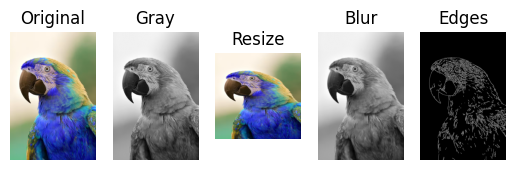

In [31]:

import cv2
import matplotlib.pyplot as plt

img = cv2.imread("image.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
resize = cv2.resize(img, (300, 300))
blur = cv2.GaussianBlur(gray, (5, 5), 0)
edges = cv2.Canny(gray, 100, 200)

images = [img, gray, resize, blur, edges]
titles = ["Original", "Gray", "Resize", "Blur", "Edges"]

for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(images[i], cmap="gray" if i in [1,3,4] else None)
    plt.title(titles[i])
    plt.axis("off")

plt.show()


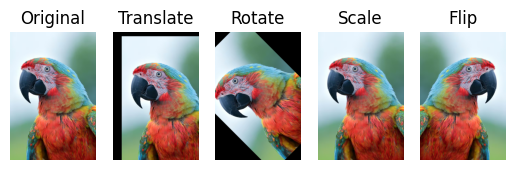

In [5]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("image.jpg")
h, w = img.shape[:2]

T = np.float32([[1, 0, 50], [0, 1, 30]])
translated = cv2.warpAffine(img, T, (w, h))

R = cv2.getRotationMatrix2D((w//2, h//2), 45, 1)
rotated = cv2.warpAffine(img, R, (w, h))

scaled = cv2.resize(img, None, fx=0.5, fy=0.5)
flipped = cv2.flip(img, 1)

for i, (name, image) in enumerate(zip(
    ["Original", "Translate", "Rotate", "Scale", "Flip"],
    [img, translated, rotated, scaled, flipped]
)):
    plt.subplot(1, 5, i+1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(name)
    plt.axis("off")

plt.show()


In [6]:

import cv2
import numpy as np

src = np.float32([
    [0, 0], [100, 0], [100, 100], [0, 100]
])

dst = np.float32([
    [10, 20], [120, 10], [110, 130], [20, 120]
])

H = cv2.getPerspectiveTransform(src, dst)

print("Homography Matrix:")
print(H)


Homography Matrix:
[[ 8.79816514e-01  1.40366972e-01  1.00000000e+01]
 [-1.18348624e-01  1.24220183e+00  2.00000000e+01]
 [-1.83486239e-03  2.01834862e-03  1.00000000e+00]]


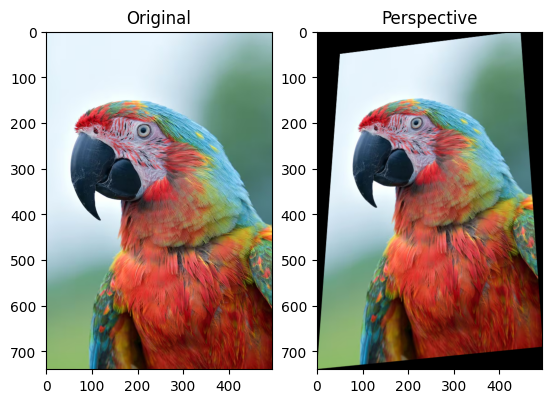

In [7]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("image.jpg")
h, w = img.shape[:2]

src = np.float32([
    [0, 0], [w-1, 0],
    [0, h-1], [w-1, h-1]
])

dst = np.float32([
    [50, 50], [w-50, 0],
    [0, h-1], [w-1, h-50]
])

M = cv2.getPerspectiveTransform(src, dst)
result = cv2.warpPerspective(img, M, (w, h))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Perspective")

plt.show()


In [39]:

import cv2
import numpy as np
import glob

objp = np.zeros((6*9, 3), np.float32)
objp[:, :2] = np.mgrid[0:9, 0:6].T.reshape(-1, 2)

objpoints, imgpoints = [], []

for file in glob.glob("chess*.jpg"):
    img = cv2.imread(file)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    found, corners = cv2.findChessboardCorners(gray, (9, 6))

    if found:
        objpoints.append(objp)
        imgpoints.append(corners)

if len(objpoints) >= 3:
    ret, camera, dist, rvecs, tvecs = cv2.calibrateCamera(
        objpoints, imgpoints, gray.shape[::-1], None, None
    )

    print("Camera Matrix:\n", camera)
    print("Distortion Coefficients:\n", dist)
else:
    print("Capture at least 3 valid chessboard images.")


Capture at least 3 valid chessboard images.


In [9]:

import cv2
import numpy as np

np.random.seed(10)

pts1 = np.random.randint(0, 300, (12, 2)).astype(np.float32)
pts2 = pts1 + [15, 5]
pts2 += np.random.normal(0, 0.5, (12, 2)).astype(np.float32)

F, mask = cv2.findFundamentalMat(
    pts1, pts2, cv2.FM_8POINT
)

print("Fundamental Matrix:")
print(F)


Fundamental Matrix:
[[-1.43989409e-06  1.73870351e-04 -7.37081610e-02]
 [-1.72016897e-04 -1.61805550e-07  2.45556224e-02]
 [ 7.46719102e-02 -2.73571264e-02  1.00000000e+00]]


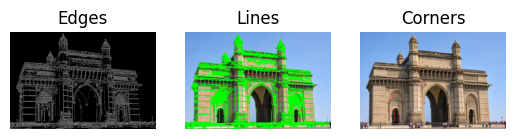

In [22]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("/content/Gateway of India Under Blue Skies.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

edges = cv2.Canny(gray, 100, 200)

lines_img = img.copy()
lines = cv2.HoughLinesP(edges, 1, np.pi/180, 80,
                        minLineLength=30, maxLineGap=10)

if lines is not None:
    for line in lines:
        # Flatten the line coordinates to guarantee we get a 1D array of 4 elements
        coords = line.ravel()
        if len(coords) == 4:
            x1, y1, x2, y2 = coords
            cv2.line(lines_img, (x1, y1), (x2, y2), (0, 255, 0), 2)

corners_img = img.copy()
corners = cv2.goodFeaturesToTrack(gray, 50, 0.01, 10)

if corners is not None:
    for x, y in np.int32(corners).reshape(-1, 2):
        cv2.circle(corners_img, (x, y), 5, (0, 0, 255), -1)

for i, (name, image) in enumerate(zip(
    ["Edges", "Lines", "Corners"],
    [edges, lines_img, corners_img]
)):
    plt.subplot(1, 3, i+1)
    plt.imshow(image if i == 0 else cv2.cvtColor(image, cv2.COLOR_BGR2RGB),
               cmap="gray" if i == 0 else None)
    plt.title(name)
    plt.axis("off")

plt.show()


Keypoints: 7683
Descriptor Shape: (7683, 128)


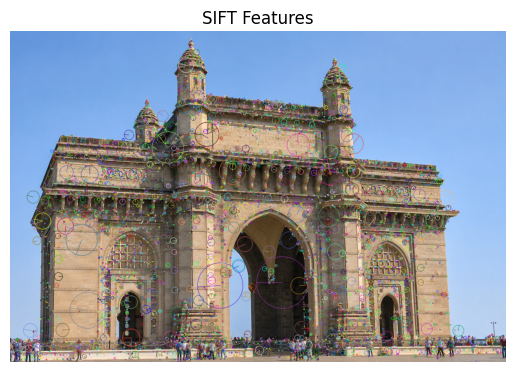

In [21]:

import cv2
import matplotlib.pyplot as plt

img = cv2.imread("/content/Gateway of India Under Blue Skies.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

sift = cv2.SIFT_create()
keypoints, descriptors = sift.detectAndCompute(gray, None)

result = cv2.drawKeypoints(
    img, keypoints, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

print("Keypoints:", len(keypoints))
print("Descriptor Shape:",
      descriptors.shape if descriptors is not None else None)

plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("SIFT Features")
plt.axis("off")
plt.show()


SURF unavailable in this OpenCV build.
HOG Feature Shape: (3780,)
Total Features: 3780


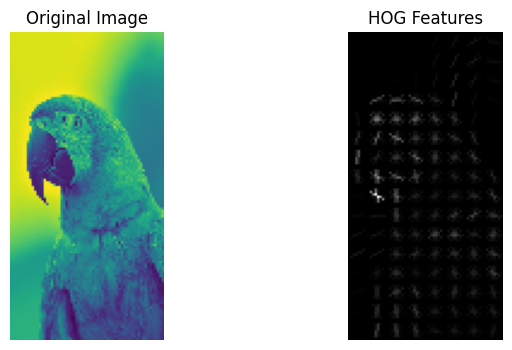

In [38]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import hog

# Read image
img = cv2.imread("image.jpg", 0)

if img is None:
    print("Image not found! Check image.jpg path.")
else:
    # SURF Feature Detection
    try:
        surf = cv2.xfeatures2d.SURF_create(400)
        kp, des = surf.detectAndCompute(img, None)

        print("SURF Keypoints:", len(kp))

        surf_img = cv2.drawKeypoints(
            img, kp, None,
            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
        )

        plt.figure(figsize=(10, 4))
        plt.imshow(surf_img, cmap="gray")
        plt.title("SURF Features")
        plt.axis("off")
        plt.show()

    except (AttributeError, cv2.error):
        print("SURF unavailable in this OpenCV build.")

    # HOG Feature Extraction
    img_resize = cv2.resize(img, (64, 128))

    features, hog_img = hog(
        img_resize,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        visualize=True
    )

    print("HOG Feature Shape:", features.shape)
    print("Total Features:", len(features))

    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(img_resize)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(hog_img, cmap="gray")
    plt.title("HOG Features")
    plt.axis("off")

    plt.show()


In [26]:
!pip install opencv-contrib-python scikit-image matplotlib numpy